In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/nyc-taxi-trip-duration/train.zip
/kaggle/input/competitions/nyc-taxi-trip-duration/test.zip
/kaggle/input/competitions/nyc-taxi-trip-duration/sample_submission.zip


In [2]:
import pyspark

print("PySpark version:", pyspark.__version__)

PySpark version: 4.0.4


In [3]:
from pyspark.sql import SparkSession
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, count, when, isnan, lit, to_timestamp
from pyspark.sql.types import DoubleType, IntegerType

In [4]:
#spark = SparkSession.builder \
    #.appName("NYC Taxi Big Data Analysis") \
    #.getOrCreate()
#spark

In [5]:
import os

# تنظیم حافظه پیش از راه‌اندازی JVM
os.environ["PYSPARK_SUBMIT_ARGS"] = (
    "--driver-memory 8g pyspark-shell"
)

from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("NYC_Taxi_Trip_Duration")
    .master("local[*]")
    .config("spark.driver.memory", "8g")
    .config("spark.sql.shuffle.partitions", "16")
    .config("spark.default.parallelism", "8")
    .getOrCreate()
)

print("Spark version:", spark.version)
print(
    "JVM max heap (GB):",
    round(
        spark._jvm.java.lang.Runtime.getRuntime().maxMemory()
        / (1024**3),
        2
    )
)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/23 11:46:48 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 4.0.4
JVM max heap (GB): 8.0


In [6]:
!unzip /kaggle/input/competitions/nyc-taxi-trip-duration/train.zip -d /kaggle/working/

Archive:  /kaggle/input/competitions/nyc-taxi-trip-duration/train.zip
  inflating: /kaggle/working/train.csv  


In [7]:
!unzip /kaggle/input/competitions/nyc-taxi-trip-duration/test.zip -d /kaggle/working/

Archive:  /kaggle/input/competitions/nyc-taxi-trip-duration/test.zip
  inflating: /kaggle/working/test.csv  


In [8]:
!ls /kaggle/working/

__notebook__.ipynb  test.csv  train.csv


In [9]:
df_train=spark.read \
    .option("header", "true") \
    .option("inferSchema", "true") \
    .csv("/kaggle/working/train.csv")

In [10]:
df_test =spark.read \
    .option("header", "true") \
    .option("inferSchema", "true") \
    .csv("/kaggle/working/test.csv")

In [11]:
df_train.printSchema()

root
 |-- id: string (nullable = true)
 |-- vendor_id: integer (nullable = true)
 |-- pickup_datetime: timestamp (nullable = true)
 |-- dropoff_datetime: timestamp (nullable = true)
 |-- passenger_count: integer (nullable = true)
 |-- pickup_longitude: double (nullable = true)
 |-- pickup_latitude: double (nullable = true)
 |-- dropoff_longitude: double (nullable = true)
 |-- dropoff_latitude: double (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- trip_duration: integer (nullable = true)



In [12]:
df_test.show(truncate=False, vertical=True,n=2)

-RECORD 0---------------------------------
 id                 | id3004672           
 vendor_id          | 1                   
 pickup_datetime    | 2016-06-30 23:59:58 
 passenger_count    | 1                   
 pickup_longitude   | -73.98812866210938  
 pickup_latitude    | 40.73202896118164   
 dropoff_longitude  | -73.99017333984375  
 dropoff_latitude   | 40.75667953491211   
 store_and_fwd_flag | N                   
-RECORD 1---------------------------------
 id                 | id3505355           
 vendor_id          | 1                   
 pickup_datetime    | 2016-06-30 23:59:53 
 passenger_count    | 1                   
 pickup_longitude   | -73.96420288085938  
 pickup_latitude    | 40.67999267578125   
 dropoff_longitude  | -73.95980834960938  
 dropoff_latitude   | 40.65540313720703   
 store_and_fwd_flag | N                   
only showing top 2 rows


In [13]:
from pyspark.sql import functions as F
from pyspark.sql.types import *

# ============================================================
# گام اول — بارگذاری مجدد و تثبیت Schema
# ============================================================
print("=== STEP 1: Reload Raw Data ===")

df_train_raw = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv("/kaggle/working/train.csv")
)

df_test_raw = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv("/kaggle/working/test.csv")
)

train_total = df_train_raw.count()
test_total = df_test_raw.count()

print(f"Train rows: {train_total:,}")
print(f"Test rows:  {test_total:,}")

print("\n--- Train Schema ---")
df_train_raw.printSchema()

print("\n--- Test Schema ---")
df_test_raw.printSchema()


# ============================================================
# گام دوم — بررسی کیفیت داده‌ها
# ============================================================
print("\n\n=== STEP 2: Quality Report ===")

def quality_report(df, name):
    print(f"\n--- {name} ---")
    
    # 1. Null values
    null_exprs = [
        F.count(F.when(F.col(c).isNull(), 1)).alias(c)
        for c in df.columns
    ]
    print("\n>> Null Counts:")
    df.select(*null_exprs).show(truncate=False, vertical=True)
    
    # 2. Duplicate IDs
    if "id" in df.columns:
        dup_ids = (
            df.groupBy("id")
            .count()
            .filter(F.col("count") > 1)
            .count()
        )
        print(f"\n>> Duplicate IDs: {dup_ids}")
    
    # 3. Numeric ranges (only for columns that exist in this DF)
    numeric_cols = [
        c for c in [
            "passenger_count",
            "pickup_longitude", "pickup_latitude",
            "dropoff_longitude", "dropoff_latitude",
            "trip_duration"
        ]
        if c in df.columns
    ]
    
    if numeric_cols:
        print("\n>> Numeric Ranges:")
        df.select(
            *[F.min(c).alias(f"{c}_min") for c in numeric_cols],
            *[F.max(c).alias(f"{c}_max") for c in numeric_cols]
        ).show(truncate=False)

quality_report(df_train_raw, "TRAIN RAW")
quality_report(df_test_raw, "TEST RAW")


# ============================================================
# گام سوم — تحلیل دقیق داده‌های پرت (فقط Train)
# ============================================================
print("\n\n=== STEP 3: Outlier Analysis (Train Only) ===")

print("\n>> Duration Percentiles:")
duration_stats = df_train_raw.select(
    F.expr(
        "percentile_approx(trip_duration, "
        "array(0.01, 0.25, 0.50, 0.75, 0.95, 0.99, 0.999), 10000)"
    ).alias("percentiles"),
    F.min("trip_duration").alias("min_duration"),
    F.max("trip_duration").alias("max_duration"),
    F.mean("trip_duration").alias("mean_duration")
)
duration_stats.show(truncate=False, vertical=True)

print("\n>> Long Trip Counts by Threshold:")
thresholds = [3600, 7200, 14400, 43200, 86400]
for threshold in thresholds:
    count_long = df_train_raw.filter(F.col("trip_duration") > threshold).count()
    pct = count_long / train_total * 100
    print(f"  > {threshold:>6,} seconds: {count_long:>6,} trips ({pct:.4f}%)")

# Check extreme cases
print("\n>> Top 10 Longest Trips:")
df_train_raw.filter(F.col("trip_duration") > 86400) \
    .select("id", "trip_duration", "pickup_datetime", "dropoff_datetime") \
    .orderBy(F.col("trip_duration").desc()) \
    .show(10, truncate=False)

# Vendor-level percentiles for extreme tail
print("\n>> Vendor-Level Duration Percentiles:")
vendor_percentiles = df_train_raw.groupBy("vendor_id").agg(
    F.expr("percentile_approx(trip_duration, 0.50)").alias("p50"),
    F.expr("percentile_approx(trip_duration, 0.75)").alias("p75"),
    F.expr("percentile_approx(trip_duration, 0.95)").alias("p95"),
    F.expr("percentile_approx(trip_duration, 0.99)").alias("p99"),
    F.expr("percentile_approx(trip_duration, 0.999)").alias("p999"),
    F.max("trip_duration").alias("max")
).orderBy("vendor_id")
vendor_percentiles.show(truncate=False)


# ============================================================
# گام چهارم — بررسی مختصات و تعداد مسافران
# ============================================================
print("\n\n=== STEP 4: Coordinates & Passenger Count ===")

# --- Passenger Count Distribution ---
print("\n>> Train Passenger Count Distribution:")
df_train_raw.groupBy("passenger_count").count().orderBy("passenger_count").show()

print("\n>> Test Passenger Count Distribution:")
df_test_raw.groupBy("passenger_count").count().orderBy("passenger_count").show()

# --- Coordinates outside approximate NYC rectangle ---
MIN_LON, MAX_LON = -74.3, -73.7
MIN_LAT, MAX_LAT = 40.4, 40.9

print("\n>> Coordinates Outside Approximate NYC Bounds:")
outside_train = df_train_raw.filter(
    ~(
        F.col("pickup_longitude").between(MIN_LON, MAX_LON) &
        F.col("pickup_latitude").between(MIN_LAT, MAX_LAT) &
        F.col("dropoff_longitude").between(MIN_LON, MAX_LON) &
        F.col("dropoff_latitude").between(MIN_LAT, MAX_LAT)
    )
)
outside_test = df_test_raw.filter(
    ~(
        F.col("pickup_longitude").between(MIN_LON, MAX_LON) &
        F.col("pickup_latitude").between(MIN_LAT, MAX_LAT) &
        F.col("dropoff_longitude").between(MIN_LON, MAX_LON) &
        F.col("dropoff_latitude").between(MIN_LAT, MAX_LAT)
    )
)
print(f"  Train: {outside_train.count():,}")
print(f"  Test:  {outside_test.count():,}")

# --- Timestamp consistency (Train only) ---
print("\n>> Timestamp Consistency (Train):")
timestamp_check = df_train_raw.withColumn(
    "duration_from_delta",
    F.col("dropoff_datetime").cast("long") - F.col("pickup_datetime").cast("long")
)

exact_mismatch = timestamp_check.filter(
    F.col("duration_from_delta") != F.col("trip_duration")
).count()

approx_mismatch = timestamp_check.filter(
    F.abs(F.col("duration_from_delta") - F.col("trip_duration")) > 60
).count()

print(f"  Exact mismatches:        {exact_mismatch:,}")
print(f"  Approx mismatches (>60s): {approx_mismatch:,}")

# --- Safe Haversine Distance ---
def add_haversine_safe(df):
    return df.withColumn("dlat", F.radians(F.col("dropoff_latitude") - F.col("pickup_latitude"))) \
             .withColumn("dlon", F.radians(F.col("dropoff_longitude") - F.col("pickup_longitude"))) \
             .withColumn("a",
                 F.sin(F.col("dlat")/2)**2 +
                 F.cos(F.radians(F.col("pickup_latitude"))) *
                 F.cos(F.radians(F.col("dropoff_latitude"))) *
                 F.sin(F.col("dlon")/2)**2
             ) \
             .withColumn("c", 2 * F.atan2(
                 F.sqrt(F.least(F.lit(1.0), F.col("a"))),
                 F.sqrt(F.greatest(F.lit(0.0), 1 - F.col("a")))
             )) \
             .withColumn("haversine_km", F.lit(6371) * F.col("c")) \
             .drop("dlat", "dlon", "a", "c")

print("\n>> Zero / Near-Zero Distance Check:")
df_train_hav = add_haversine_safe(df_train_raw)
df_test_hav = add_haversine_safe(df_test_raw)

zero_dist_train = df_train_hav.filter(F.col("haversine_km") == 0).count()
very_small_dist_train = df_train_hav.filter(F.col("haversine_km") < 0.05).count()  # less than 50 meters

zero_dist_test = df_test_hav.filter(F.col("haversine_km") == 0).count()
very_small_dist_test = df_test_hav.filter(F.col("haversine_km") < 0.05).count()

print(f"  Train exact zero-distance:     {zero_dist_train:,}")
print(f"  Train distance < 0.05 km:      {very_small_dist_train:,}")
print(f"  Test exact zero-distance:      {zero_dist_test:,}")
print(f"  Test distance < 0.05 km:       {very_small_dist_test:,}")

# --- Same pickup/dropoff flag (before any removal) ---
print("\n>> Same Pickup/Dropoff Flag (exact coordinates):")
df_train_raw.withColumn(
    "same_pickup_dropoff",
    F.when(
        (F.col("pickup_longitude") == F.col("dropoff_longitude")) &
        (F.col("pickup_latitude") == F.col("dropoff_latitude")), 1
    ).otherwise(0)
).groupBy("same_pickup_dropoff").count().show()

print("\n=== DIAGNOSTIC COMPLETE ===")
print("No rows were removed. Review the numbers above to decide on cleaning rules.")

=== STEP 1: Reload Raw Data ===


Train rows: 1,458,644
Test rows:  625,134

--- Train Schema ---
root
 |-- id: string (nullable = true)
 |-- vendor_id: integer (nullable = true)
 |-- pickup_datetime: timestamp (nullable = true)
 |-- dropoff_datetime: timestamp (nullable = true)
 |-- passenger_count: integer (nullable = true)
 |-- pickup_longitude: double (nullable = true)
 |-- pickup_latitude: double (nullable = true)
 |-- dropoff_longitude: double (nullable = true)
 |-- dropoff_latitude: double (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- trip_duration: integer (nullable = true)


--- Test Schema ---
root
 |-- id: string (nullable = true)
 |-- vendor_id: integer (nullable = true)
 |-- pickup_datetime: timestamp (nullable = true)
 |-- passenger_count: integer (nullable = true)
 |-- pickup_longitude: double (nullable = true)
 |-- pickup_latitude: double (nullable = true)
 |-- dropoff_longitude: double (nullable = true)
 |-- dropoff_latitude: double (nullable = true)
 |-- store_and_fwd_flag: 

-RECORD 0-----------------
 id                 | 0   
 vendor_id          | 0   
 pickup_datetime    | 0   
 dropoff_datetime   | 0   
 passenger_count    | 0   
 pickup_longitude   | 0   
 pickup_latitude    | 0   
 dropoff_longitude  | 0   
 dropoff_latitude   | 0   
 store_and_fwd_flag | 0   
 trip_duration      | 0   




>> Duplicate IDs: 0

>> Numeric Ranges:


+-------------------+--------------------+-------------------+---------------------+--------------------+-----------------+-------------------+--------------------+-------------------+---------------------+--------------------+-----------------+
|passenger_count_min|pickup_longitude_min|pickup_latitude_min|dropoff_longitude_min|dropoff_latitude_min|trip_duration_min|passenger_count_max|pickup_longitude_max|pickup_latitude_max|dropoff_longitude_max|dropoff_latitude_max|trip_duration_max|
+-------------------+--------------------+-------------------+---------------------+--------------------+-----------------+-------------------+--------------------+-------------------+---------------------+--------------------+-----------------+
|0                  |-121.93334197998047 |34.35969543457031  |-121.93330383300781  |32.1811408996582    |1                |9                  |-61.33552932739258  |51.88108444213867  |-61.33552932739258   |43.92102813720703   |3526282          |
+---------------

...

  Train: 1,685


  Test:  656

>> Timestamp Consistency (Train):


  Exact mismatches:        0
  Approx mismatches (>60s): 0

>> Zero / Near-Zero Distance Check:


  Train exact zero-distance:     5,897
  Train distance < 0.05 km:      11,329
  Test exact zero-distance:      2,475
  Test distance < 0.05 km:       4,842

>> Same Pickup/Dropoff Flag (exact coordinates):


+-------------------+-------+
|same_pickup_dropoff|  count|
+-------------------+-------+
|                  1|   5897|
|                  0|1452747|
+-------------------+-------+


=== DIAGNOSTIC COMPLETE ===
No rows were removed. Review the numbers above to decide on cleaning rules.


In [14]:
# ============================================================
# NYC Taxi — Complete Feature Engineering Pipeline
# Includes: temporal, spatial, interactions, cyclical encoding
# Leakage-safe + time-based split + Kaggle-ready
# ============================================================
import time
import math
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType, FloatType
from pyspark.ml.feature import VectorAssembler, StringIndexer

TWO_PI = 2 * math.pi

# ---------------------- constants ---------------------------
NYC_BOUNDS       = {"lon": (-74.3, -73.7),   "lat": (40.4, 40.9)}
JFK_BOUNDS       = {"lon": (-73.82, -73.74), "lat": (40.62, 40.68)}
LGA_BOUNDS       = {"lon": (-73.90, -73.84), "lat": (40.75, 40.80)}
MANHATTAN_BOUNDS = {"lon": (-74.02, -73.90),"lat": (40.70, 40.88)}

MAX_DURATION_SEC = 86400
MIN_DURATION_SEC = 30

LEAKAGE_INPUT_COLS = ["dropoff_datetime", "duration_from_delta", "duration_outlier"]
TARGET_COLS        = ["trip_duration", "log_trip_duration"]

FEATURE_COLS = [
    # vendor
    "vendor_id",
    # passenger
    "passenger_count",
    # raw coordinates
    "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude",
    # store flag
    "store_and_fwd_flag_y",
    # temporal raw (useful for tree splits)
    "pickup_hour", "pickup_dayofweek", "pickup_month",
    # temporal flags
    "is_weekend", "is_rush_hour", "is_late_night",
    # cyclical encodings
    "pickup_hour_sin", "pickup_hour_cos",
    "pickup_dow_sin",  "pickup_dow_cos",
    "pickup_month_sin","pickup_month_cos",
    # spatial
    "haversine_km", "distance_bin",
    "is_jfk_pickup", "is_lga_pickup", "is_airport_pickup",
    "is_manhattan", "slow_trip_indicator",
    # interactions
    "is_group_trip", "vendor_rush", "vendor_x_group_idx",
]

# ---------------------- helpers -----------------------------
def check_nulls(df):
    exprs = []
    for f in df.schema.fields:
        c = f.name
        if isinstance(f.dataType, (DoubleType, FloatType)):
            exprs.append(F.count(F.when(F.col(c).isNull() | F.isnan(c), c)).alias(c))
        else:
            exprs.append(F.count(F.when(F.col(c).isNull(), c)).alias(c))
    return df.select(*exprs)

# ---------------------- feature blocks ----------------------
def add_temporal_features(df):
    df = df.withColumn("pickup_datetime", F.to_timestamp("pickup_datetime"))
    df = df.withColumn("pickup_hour",      F.hour("pickup_datetime"))
    df = df.withColumn("pickup_dayofweek", F.dayofweek("pickup_datetime"))
    df = df.withColumn("pickup_month",     F.month("pickup_datetime"))
    df = df.withColumn("is_weekend",
        F.when(F.col("pickup_dayofweek").isin([1, 7]), 1).otherwise(0))
    df = df.withColumn("is_rush_hour",
        F.when(F.col("pickup_hour").between(7, 9) |
               F.col("pickup_hour").between(17, 19), 1).otherwise(0))
    df = df.withColumn("is_late_night",
        F.when((F.col("pickup_hour") >= 22) | (F.col("pickup_hour") <= 4), 1).otherwise(0))
    return df

def add_cyclical_features(df):
    """
    sin/cos encodings for periodic features.
    Correct wrap-around:
      hour 23 ↔ 0, Saturday ↔ Sunday, December ↔ January.
    Spark dayofweek = 1=Sunday..7=Saturday → normalize to 0..6.
    Spark month     = 1..12                → normalize to 0..11.
    """
    # hour (0-23): direct formula
    df = df.withColumn("pickup_hour_sin",
        F.sin(F.lit(TWO_PI) * F.col("pickup_hour") / F.lit(24.0)))
    df = df.withColumn("pickup_hour_cos",
        F.cos(F.lit(TWO_PI) * F.col("pickup_hour") / F.lit(24.0)))

    # dayofweek (1-7): normalize to 0-6
    dow_norm = (F.col("pickup_dayofweek") - F.lit(1)).cast("double")
    df = df.withColumn("pickup_dow_sin",
        F.sin(F.lit(TWO_PI) * dow_norm / F.lit(7.0)))
    df = df.withColumn("pickup_dow_cos",
        F.cos(F.lit(TWO_PI) * dow_norm / F.lit(7.0)))

    # month (1-12): normalize to 0-11
    month_norm = (F.col("pickup_month") - F.lit(1)).cast("double")
    df = df.withColumn("pickup_month_sin",
        F.sin(F.lit(TWO_PI) * month_norm / F.lit(12.0)))
    df = df.withColumn("pickup_month_cos",
        F.cos(F.lit(TWO_PI) * month_norm / F.lit(12.0)))

    return df

def add_spatial_features(df):
    lon1, lat1 = F.radians("pickup_longitude"),  F.radians("pickup_latitude")
    lon2, lat2 = F.radians("dropoff_longitude"), F.radians("dropoff_latitude")
    a = F.sin((lat2-lat1)/2)**2 + F.cos(lat1)*F.cos(lat2)*F.sin((lon2-lon1)/2)**2
    df = df.withColumn("haversine_km", F.lit(2*6371.0)*F.atan2(F.sqrt(a), F.sqrt(1-a)))
    df = df.withColumn("distance_bin", F.floor(F.col("haversine_km")).cast("int"))
    df = df.withColumn("is_jfk_pickup",
        F.when(F.col("pickup_longitude").between(*JFK_BOUNDS["lon"]) &
               F.col("pickup_latitude").between(*JFK_BOUNDS["lat"]), 1).otherwise(0))
    df = df.withColumn("is_lga_pickup",
        F.when(F.col("pickup_longitude").between(*LGA_BOUNDS["lon"]) &
               F.col("pickup_latitude").between(*LGA_BOUNDS["lat"]), 1).otherwise(0))
    df = df.withColumn("is_airport_pickup", F.greatest("is_jfk_pickup", "is_lga_pickup"))
    df = df.withColumn("is_manhattan",
        F.when(F.col("pickup_longitude").between(*MANHATTAN_BOUNDS["lon"]) &
               F.col("pickup_latitude").between(*MANHATTAN_BOUNDS["lat"]), 1).otherwise(0))
    df = df.withColumn("slow_trip_indicator",
        F.when((F.col("is_rush_hour") == 1) & (F.col("haversine_km") < 3), 1).otherwise(0))
    return df

def add_interaction_features(df):
    df = df.withColumn("is_group_trip",
        F.when(F.col("passenger_count") >= 2, 1).otherwise(0))
    df = df.withColumn("vendor_x_group",
        F.concat(F.col("vendor_id").cast("string"), F.lit("_"),
                 F.col("is_group_trip").cast("string")))
    df = df.withColumn("vendor_rush",
        F.when((F.col("vendor_id") == 2) & (F.col("is_rush_hour") == 1), 1).otherwise(0))
    return df

def build_features(df, cap_passengers=True, drop_raw_flag=True):
    df = add_temporal_features(df)
    df = add_cyclical_features(df)   # ← cyclical after temporal
    df = add_spatial_features(df)
    df = df.withColumn("store_and_fwd_flag_y",
        F.when(F.col("store_and_fwd_flag") == "Y", 1).otherwise(0))
    if drop_raw_flag:
        df = df.drop("store_and_fwd_flag")
    if cap_passengers:
        df = df.withColumn("passenger_count",
            F.when(F.col("passenger_count") > 6, 6).otherwise(F.col("passenger_count")))
    df = add_interaction_features(df)
    return df

# ---------------------- train-only cleaning -----------------
def compute_clean_params(train_df, iqr_k=1.5):
    q1, q3 = train_df.approxQuantile("trip_duration", [0.25, 0.75], 0.001)
    iqr = q3 - q1
    return {
        "iqr_lower": max(MIN_DURATION_SEC, q1 - iqr_k * iqr),
        "iqr_upper": min(MAX_DURATION_SEC, q3 + iqr_k * iqr),
    }

def clean_train(df, params, use_iqr_filter=False):
    df = df.filter(
        (F.col("passenger_count") > 0) &
        (F.col("haversine_km") > 0) &
        (F.col("trip_duration").between(MIN_DURATION_SEC, MAX_DURATION_SEC))
    )
    if use_iqr_filter:
        df = df.filter(
            F.col("trip_duration").between(params["iqr_lower"], params["iqr_upper"]))
    df = df.withColumn("log_trip_duration", F.log1p("trip_duration"))
    return df

# ---------------------- time split --------------------------
def time_based_split(df, split_ts="2016-06-01 00:00:00"):
    ts = F.lit(split_ts).cast("timestamp")
    return (df.filter(F.col("pickup_datetime") < ts),
            df.filter(F.col("pickup_datetime") >= ts))

# ---------------------- model-ready data -------------------
def assemble_features(train_df, other_dfs=None, feature_cols=None, keep_labels=True):
    feature_cols = feature_cols or FEATURE_COLS

    indexer_model = StringIndexer(
        inputCol="vendor_x_group", outputCol="vendor_x_group_idx",
        handleInvalid="keep",
    ).fit(train_df)

    assembler = VectorAssembler(
        inputCols=feature_cols, outputCol="features", handleInvalid="keep",
    )

    def _apply(df):
        df = indexer_model.transform(df)
        df = assembler.transform(df)
        keep = ["id", "features"]
        if keep_labels:
            for lbl in TARGET_COLS:
                if lbl in df.columns:
                    keep.append(lbl)
        return df.select(*keep)

    out = {"train": _apply(train_df)}
    if other_dfs:
        for name, d in other_dfs.items():
            out[name] = _apply(d)
    out["_indexer_model"] = indexer_model  # for debugging/mapping
    return out

# ---------------------- end-to-end --------------------------
def run_pipeline(spark, train_path, test_path, use_iqr_filter=False):
    def _read(p):
        return spark.read.option("header", True).option("inferSchema", True).csv(p)

    df_train_raw = _read(train_path)
    df_test_raw  = _read(test_path)

    # 1. identical features on both
    df_train = build_features(df_train_raw)
    df_test  = build_features(df_test_raw)

    # 2. drop INPUT leakage only
    df_train = df_train.drop(*[c for c in LEAKAGE_INPUT_COLS if c in df_train.columns])

    # 3. time-based split
    train_part, valid_part = time_based_split(df_train, "2016-06-01 00:00:00")

    # 4. stats from train portion only
    params = compute_clean_params(train_part)

    # 5. clean both
    train_part = clean_train(train_part, params, use_iqr_filter)
    valid_part = clean_train(valid_part, params, use_iqr_filter)

    # 6. test: no filtering, no target
    df_test = df_test.select("id", *[c for c in df_test.columns
                                     if c not in TARGET_COLS + LEAKAGE_INPUT_COLS])

    # 7. assemble
    ready = assemble_features(
        train_part,
        other_dfs={"valid": valid_part, "test": df_test},
        keep_labels=True,
    )
    ready["params"] = params
    return ready


# ============================================================
# ✅ RUN
# ============================================================
spark = SparkSession.builder.appName("NYC-Taxi-Features").getOrCreate()
spark.sparkContext.setLogLevel("WARN")

t0 = time.time()
data = run_pipeline(
    spark,
    train_path="/kaggle/working/train.csv",
    test_path="/kaggle/working/test.csv",
)
print(f"✅ Pipeline done in {time.time()-t0:.1f}s")

# ---------- summary ----------
print("\nCleaning params:", data["params"])
print(f"\nFeature count: {len(FEATURE_COLS)}")
print("Features:")
for i, c in enumerate(FEATURE_COLS):
    print(f"  [{i:2d}] {c}")

print("\n--- TRAIN ---")
data["train"].printSchema()
print(f"Rows: {data['train'].count():,}")

print("\n--- VALID ---")
print(f"Rows: {data['valid'].count():,}")

print("\n--- TEST ---")
print(f"Rows: {data['test'].count():,}")

# ---------- sanity checks ----------
assert "log_trip_duration" in data["train"].columns, "train label missing!"
assert "log_trip_duration" in data["valid"].columns, "valid label missing!"
assert "log_trip_duration" not in data["test"].columns, "test should not have label!"
assert data["test"].count() == spark.read.csv(
    "/kaggle/working/test.csv", header=True
).count(), "test rows lost!"

print("\n✅ All checks passed")

# ---------- show cyclical sanity on real data ----------
print("\n=== Cyclical encoding sanity (hour 0 vs 23) ===")
from pyspark.ml.functions import vector_to_array
tmp = data["train"].select(vector_to_array("features").alias("arr"))
expanded = tmp.select(
    *[F.col("arr")[i].alias(name) for i, name in enumerate(FEATURE_COLS)]
)
expanded.filter(F.col("pickup_hour").isin([0, 23])) \
    .groupBy("pickup_hour") \
    .agg(
        F.mean("pickup_hour_sin").alias("hour_sin"),
        F.mean("pickup_hour_cos").alias("hour_cos"),
    ).orderBy("pickup_hour").show()

# ---------- show all 29 features for 3 rows ----------
print("\n=== First 3 rows, all features ===")
sample = expanded.limit(3).toPandas().T
sample.columns = [f"row {j+1}" for j in range(3)]
sample.index.name = "feature"
print(sample.to_string())

print("\n🎉 Pipeline ready — 29 features, cyclical encodings included.")

26/10/23 11:48:25 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.


✅ Pipeline done in 13.7s

Cleaning params: {'iqr_lower': 30, 'iqr_upper': 2066.5}

Feature count: 29
Features:
  [ 0] vendor_id
  [ 1] passenger_count
  [ 2] pickup_longitude
  [ 3] pickup_latitude
  [ 4] dropoff_longitude
  [ 5] dropoff_latitude
  [ 6] store_and_fwd_flag_y
  [ 7] pickup_hour
  [ 8] pickup_dayofweek
  [ 9] pickup_month
  [10] is_weekend
  [11] is_rush_hour
  [12] is_late_night
  [13] pickup_hour_sin
  [14] pickup_hour_cos
  [15] pickup_dow_sin
  [16] pickup_dow_cos
  [17] pickup_month_sin
  [18] pickup_month_cos
  [19] haversine_km
  [20] distance_bin
  [21] is_jfk_pickup
  [22] is_lga_pickup
  [23] is_airport_pickup
  [24] is_manhattan
  [25] slow_trip_indicator
  [26] is_group_trip
  [27] vendor_rush
  [28] vendor_x_group_idx

--- TRAIN ---
root
 |-- id: string (nullable = true)
 |-- features: vector (nullable = true)
 |-- trip_duration: integer (nullable = true)
 |-- log_trip_duration: double (nullable = true)



Rows: 1,216,551

--- VALID ---


Rows: 232,722

--- TEST ---
Rows: 625,134

✅ All checks passed

=== Cyclical encoding sanity (hour 0 vs 23) ===


26/10/23 11:48:46 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-----------+-------------------+------------------+
|pickup_hour|           hour_sin|          hour_cos|
+-----------+-------------------+------------------+
|        0.0|                0.0|               1.0|
|       23.0|-0.2588190451024869|0.9659258262890933|
+-----------+-------------------+------------------+


=== First 3 rows, all features ===
                          row 1      row 2         row 3
feature                                                 
vendor_id              2.000000   2.000000  2.000000e+00
passenger_count        1.000000   1.000000  1.000000e+00
pickup_longitude     -73.982155 -73.979027 -7.401004e+01
pickup_latitude       40.767937  40.763939  4.071997e+01
dropoff_longitude    -73.964630 -74.005333 -7.401227e+01
dropoff_latitude      40.765602  40.710087  4.070672e+01
store_and_fwd_flag_y   0.000000   0.000000  0.000000e+00
pickup_hour           17.000000  11.000000  1.900000e+01
pickup_dayofweek       2.000000   3.000000  4.000000e+00
pickup_month      

In [15]:
# ============================================================
# SINGLE-ROW FEATURE INSPECTOR
# ============================================================
import numpy as np
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler, StringIndexer
import math
# ---------- config ----------
ROW_INDEX = 0       
# ---------- bounds (same as your code) ----------
NYC_BOUNDS       = {"lon": (-74.3, -73.7),   "lat": (40.4, 40.9)}
JFK_BOUNDS       = {"lon": (-73.82, -73.74), "lat": (40.62, 40.68)}
LGA_BOUNDS       = {"lon": (-73.90, -73.84), "lat": (40.75, 40.80)}
MANHATTAN_BOUNDS = {"lon": (-74.02, -73.90),"lat": (40.70, 40.88)}

FEATURE_COLS = [
    "vendor_id", "passenger_count",
    "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude",
    "store_and_fwd_flag_y",
    "pickup_hour", "pickup_dayofweek", "pickup_month",
    "is_weekend", "is_rush_hour", "is_late_night",
    "haversine_km", "distance_bin",
    "is_jfk_pickup", "is_lga_pickup", "is_airport_pickup",
    "is_manhattan", "slow_trip_indicator",
    "is_group_trip", "vendor_rush", "vendor_x_group_idx",
]

# ---------- helpers ----------
def section(title):
    print("\n" + "=" * 90)
    print(f"  {title}")
    print("=" * 90)

def row(v, w=32, note=""):
    s = f"{v!s:>{w}}"
    print(f"{s}   {note}" if note else s)

# ---------- 1) load one row from raw ----------
train_raw = spark.read.option("header", True).option("inferSchema", True) \
    .csv("/kaggle/working/train.csv")

target_id = train_raw.select("id").collect()[ROW_INDEX][0]
raw_one = train_raw.filter(F.col("id") == target_id).limit(1)
raw_row = raw_one.collect()[0]

section(f"STEP 1 — RAW INPUT (row #{ROW_INDEX}, id = {target_id})")
print(f"{'column':<26} {'value':<32} {'type':<10} {'use'}")
print("-" * 90)
raw_meta = [
    ("id",                  "IDENTIFIER — not a feature (submission only)"),
    ("vendor_id",           "FEATURE (raw)"),
    ("pickup_datetime",     "SOURCE for temporal features (dropped)"),
    ("dropoff_datetime",    "LEAKAGE — dropped"),
    ("passenger_count",     "FEATURE (raw)"),
    ("pickup_longitude",    "FEATURE (raw)"),
    ("pickup_latitude",     "FEATURE (raw)"),
    ("dropoff_longitude",   "FEATURE (raw)"),
    ("dropoff_latitude",    "FEATURE (raw)"),
    ("store_and_fwd_flag",  "SOURCE for is_store_fwd (dropped)"),
    ("trip_duration",       "TARGET — never a feature"),
]
for col_name, use in raw_meta:
    v = raw_row[col_name]
    t = type(v).__name__
    print(f"{col_name:<26} {str(v):<32} {t:<10} {use}")

# ---------- 2) feature pipeline (same logic as your code) ----------
def add_temporal(df):
    df = df.withColumn("pickup_datetime", F.to_timestamp("pickup_datetime"))
    df = df.withColumn("pickup_hour",      F.hour("pickup_datetime"))
    df = df.withColumn("pickup_dayofweek", F.dayofweek("pickup_datetime"))
    df = df.withColumn("pickup_month",     F.month("pickup_datetime"))
    df = df.withColumn("is_weekend",
        F.when(F.col("pickup_dayofweek").isin([1,7]), 1).otherwise(0))
    df = df.withColumn("is_rush_hour",
        F.when(F.col("pickup_hour").between(7,9) |
               F.col("pickup_hour").between(17,19), 1).otherwise(0))
    df = df.withColumn("is_late_night",
        F.when((F.col("pickup_hour")>=22) | (F.col("pickup_hour")<=4), 1).otherwise(0))
    return df

def add_spatial(df):
    lon1, lat1 = F.radians("pickup_longitude"),  F.radians("pickup_latitude")
    lon2, lat2 = F.radians("dropoff_longitude"), F.radians("dropoff_latitude")
    a = F.sin((lat2-lat1)/2)**2 + F.cos(lat1)*F.cos(lat2)*F.sin((lon2-lon1)/2)**2
    df = df.withColumn("haversine_km",
        F.lit(2*6371.0) * F.atan2(F.sqrt(a), F.sqrt(1-a)))
    df = df.withColumn("distance_bin", F.floor(F.col("haversine_km")).cast("int"))
    df = df.withColumn("is_jfk_pickup",
        F.when(F.col("pickup_longitude").between(*JFK_BOUNDS["lon"]) &
               F.col("pickup_latitude").between(*JFK_BOUNDS["lat"]), 1).otherwise(0))
    df = df.withColumn("is_lga_pickup",
        F.when(F.col("pickup_longitude").between(*LGA_BOUNDS["lon"]) &
               F.col("pickup_latitude").between(*LGA_BOUNDS["lat"]), 1).otherwise(0))
    df = df.withColumn("is_airport_pickup", F.greatest("is_jfk_pickup", "is_lga_pickup"))
    df = df.withColumn("is_manhattan",
        F.when(F.col("pickup_longitude").between(*MANHATTAN_BOUNDS["lon"]) &
               F.col("pickup_latitude").between(*MANHATTAN_BOUNDS["lat"]), 1).otherwise(0))
    df = df.withColumn("slow_trip_indicator",
        F.when((F.col("is_rush_hour")==1) & (F.col("haversine_km")<3), 1).otherwise(0))
    return df

def add_interactions(df):
    df = df.withColumn("is_group_trip",
        F.when(F.col("passenger_count")>=2, 1).otherwise(0))
    df = df.withColumn("vendor_x_group",
        F.concat(F.col("vendor_id").cast("string"), F.lit("_"),
                 F.col("is_group_trip").cast("string")))
    df = df.withColumn("vendor_rush",
        F.when((F.col("vendor_id")==2) & (F.col("is_rush_hour")==1), 1).otherwise(0))
    return df

def build_features(df):
    df = add_temporal(df)
    df = add_spatial(df)
    df = df.withColumn("store_and_fwd_flag_y",
        F.when(F.col("store_and_fwd_flag")=="Y", 1).otherwise(0))
    df = df.drop("store_and_fwd_flag")
    df = df.withColumn("passenger_count",
        F.when(F.col("passenger_count")>6, 6).otherwise(F.col("passenger_count")))
    df = add_interactions(df)
    return df

# ---------- 3) apply to the row ----------
raw_one_feat = build_features(raw_one)
# fit StringIndexer on just this one row is meaningless → instead, fit on full train (first 1000 rows is enough)
sample_for_indexer = build_features(train_raw.limit(1000))
indexer = StringIndexer(inputCol="vendor_x_group", outputCol="vendor_x_group_idx",
                        handleInvalid="keep")
indexer_model = indexer.fit(sample_for_indexer)
row_df = indexer_model.transform(raw_one_feat)

# extract values
row_dict = row_df.collect()[0].asDict()

# ---------- 4) describe each feature ----------
feature_meta = {
    "vendor_id": (
        "Identifier of taxi vendor",
        "1 = vendor A, 2 = vendor B",
        "categorical int",
    ),
    "passenger_count": (
        "Number of passengers (0-6, capped)",
        "0-6 (7,8 → 6)",
        "categorical int",
    ),
    "pickup_longitude": (
        "Longitude of pickup point (NYC ≈ -74)",
        "float, -74.3..-73.7",
        "continuous",
    ),
    "pickup_latitude": (
        "Latitude of pickup point (NYC ≈ 40.7)",
        "float, 40.4..40.9",
        "continuous",
    ),
    "dropoff_longitude": (
        "Longitude of dropoff point",
        "float, -74.3..-73.7",
        "continuous",
    ),
    "dropoff_latitude": (
        "Latitude of dropoff point",
        "float, 40.4..40.9",
        "continuous",
    ),
    "store_and_fwd_flag_y": (
        "1 if trip was stored offline before sending (Vendor 1 only)",
        "0 or 1",
        "binary",
    ),
    "pickup_hour": (
        "Hour of day of pickup",
        "0-23 (0=midnight, 12=noon)",
        "cyclical int",
    ),
    "pickup_dayofweek": (
        "Day of week of pickup (Spark: 1=Sunday)",
        "1=Sun, 2=Mon, ..., 7=Sat",
        "cyclical int",
    ),
    "pickup_month": (
        "Month of pickup (dataset spans Jan-Jun only)",
        "1-6",
        "cyclical int",
    ),
    "is_weekend": (
        "1 if Saturday or Sunday",
        "0 or 1",
        "binary",
    ),
    "is_rush_hour": (
        "1 if pickup hour is in 7-9 or 17-19",
        "0 or 1",
        "binary",
    ),
    "is_late_night": (
        "1 if pickup hour is in 22-4",
        "0 or 1",
        "binary",
    ),
    "haversine_km": (
        "Straight-line distance pickup → dropoff (km)",
        "0..~25",
        "continuous",
    ),
    "distance_bin": (
        "Floor of haversine_km (distance bin)",
        "0-30",
        "categorical int",
    ),
    "is_jfk_pickup": (
        "1 if pickup inside JFK airport box",
        "0 or 1",
        "binary",
    ),
    "is_lga_pickup": (
        "1 if pickup inside LaGuardia airport box",
        "0 or 1",
        "binary",
    ),
    "is_airport_pickup": (
        "1 if pickup at JFK OR LGA (greatest of previous two)",
        "0 or 1",
        "binary (redundant)",
    ),
    "is_manhattan": (
        "1 if pickup inside Manhattan box",
        "0 or 1",
        "binary",
    ),
    "slow_trip_indicator": (
        "1 if rush_hour AND haversine_km < 3 (short trip in traffic)",
        "0 or 1",
        "binary",
    ),
    "is_group_trip": (
        "1 if passenger_count >= 2",
        "0 or 1",
        "binary",
    ),
    "vendor_rush": (
        "1 if vendor_id==2 AND is_rush_hour==1 (only one combo!)",
        "0 or 1",
        "binary (weak)",
    ),
    "vendor_x_group_idx": (
        "StringIndexer code for vendor_x_group = 'vendorId_groupFlag'",
        "0-3",
        "categorical int",
    ),
}

section("STEP 2 — DERIVED FEATURES (each with explanation)")
print(f"{'#':>3}  {'feature':<22} {'value':<24} {'type':<18} explanation")
print("-" * 110)
for i, f in enumerate(FEATURE_COLS):
    v = row_dict.get(f)
    if isinstance(v, float):
        v_str = f"{v:.6f}"
    else:
        v_str = str(v)
    desc, rng, typ = feature_meta[f]
    print(f"{i:>3}  {f:<22} {v_str:<24} {typ:<18} {desc}")

# ---------- 5) intermediate (non-feature) columns ----------
section("STEP 3 — INTERMEDIATE COLUMNS (built but NOT used as features)")
intermediate = [
    "pickup_datetime", "dropoff_datetime",
    "vendor_x_group",
    "trip_duration", "log_trip_duration",
    "haversine_km", "distance_bin",
]
print(f"{'column':<24} {'value':<32} {'why it exists'}")
print("-" * 90)
notes = {
    "pickup_datetime":     "source for hour/day/month — dropped after",
    "dropoff_datetime":    "LEAKAGE — never a feature",
    "vendor_x_group":      "raw string → indexed to vendor_x_group_idx",
    "trip_duration":       "TARGET",
    "log_trip_duration":   "TARGET (log1p)",
    "haversine_km":        "already in features list",
    "distance_bin":        "already in features list",
}
for c in intermediate:
    if c in row_dict:
        v = row_dict[c]
        v_str = f"{v:.4f}" if isinstance(v, float) else str(v)
        print(f"{c:<24} {v_str:<32} {notes[c]}")

# ---------- 6) final feature vector ----------
section("STEP 4 — FINAL FEATURE VECTOR (what the model actually sees)")
assembler = VectorAssembler(inputCols=FEATURE_COLS, outputCol="features",
                            handleInvalid="keep")
final_vec = assembler.transform(row_df).select("features").collect()[0][0]
vec = final_vec.toArray()

print(f"Vector length: {len(vec)}")
print(f"{'pos':>3}  {'feature':<22} {'value':>16}   range")
print("-" * 70)
for i, (name, val) in enumerate(zip(FEATURE_COLS, vec)):
    meta = feature_meta[name]
    print(f"{i:>3}  {name:<22} {val:>16.6f}   {meta[1]}")

print("\nRaw vector:")
print(np.array2string(vec, precision=4, separator=", ", max_line_width=100))

# ---------- 7) what was NOT used (leakage & identifiers) ----------
section("STEP 5 — COLUMNS NOT USED FOR MODELING")
excluded = [
    ("id",                 "Identifier — used only in submission file"),
    ("pickup_datetime",    "Timestamp — dropped after temporal extraction"),
    ("dropoff_datetime",   "LEAKAGE — encodes target via subtraction"),
    ("trip_duration",      "TARGET (raw seconds)"),
    ("log_trip_duration",  "TARGET (log1p seconds)"),
    ("duration_from_delta","LEAKAGE — equals trip_duration"),
    ("duration_outlier",   "LEAKAGE — derived from trip_duration"),
    ("store_and_fwd_flag", "string version — replaced by _y binary"),
    ("vendor_x_group",     "string — replaced by _idx integer"),
]
print(f"{'column':<24} {'reason'}")
print("-" * 80)
for c, why in excluded:
    print(f"{c:<24} {why}")
# ---------- 8) sanity: predictions context ----------
section("STEP 6 — CONTEXT FOR THIS TRIP")
td = row_dict.get("trip_duration")
log_td = row_dict.get("log_trip_duration")

if log_td is None and td is not None:
    log_td = math.log1p(td)   
    note = "(computed on the fly — not present in build_features)"
else:
    note = ""

print(f"Actual trip_duration : {td} seconds")
print(f"Actual log1p(target) : {log_td:.4f}  {note}")
print(f"Average speed        : "
      f"{row_dict['haversine_km'] / (td/3600):.2f} km/h")
print(f"Trip classification  : "
      f"{'AIRPORT' if row_dict['is_airport_pickup'] else ('MANHATTAN' if row_dict['is_manhattan'] else 'OUTER')}")
print(f"Time context         : "
      f"{'Weekend' if row_dict['is_weekend'] else 'Weekday'} | "
      f"{'Rush' if row_dict['is_rush_hour'] else 'Off-peak'} | "
      f"{'Late night' if row_dict['is_late_night'] else 'Normal hours'}")

print("\n✅ Inspection complete.\n")


  STEP 1 — RAW INPUT (row #0, id = id2875421)
column                     value                            type       use
------------------------------------------------------------------------------------------
id                         id2875421                        str        IDENTIFIER — not a feature (submission only)
vendor_id                  2                                int        FEATURE (raw)
pickup_datetime            2016-03-14 17:24:55              datetime   SOURCE for temporal features (dropped)
dropoff_datetime           2016-03-14 17:32:30              datetime   LEAKAGE — dropped
passenger_count            1                                int        FEATURE (raw)
pickup_longitude           -73.9821548461914                float      FEATURE (raw)
pickup_latitude            40.76793670654297                float      FEATURE (raw)
dropoff_longitude          -73.96463012695312               float      FEATURE (raw)
dropoff_latitude           40.765602111816406  


  STEP 2 — DERIVED FEATURES (each with explanation)
  #  feature                value                    type               explanation
--------------------------------------------------------------------------------------------------------------
  0  vendor_id              2                        categorical int    Identifier of taxi vendor
  1  passenger_count        1                        categorical int    Number of passengers (0-6, capped)
  2  pickup_longitude       -73.982155               continuous         Longitude of pickup point (NYC ≈ -74)
  3  pickup_latitude        40.767937                continuous         Latitude of pickup point (NYC ≈ 40.7)
  4  dropoff_longitude      -73.964630               continuous         Longitude of dropoff point
  5  dropoff_latitude       40.765602                continuous         Latitude of dropoff point
  6  store_and_fwd_flag_y   0                        binary             1 if trip was stored offline before sending (Vendor 1 only

Vector length: 23
pos  feature                           value   range
----------------------------------------------------------------------
  0  vendor_id                      2.000000   1 = vendor A, 2 = vendor B
  1  passenger_count                1.000000   0-6 (7,8 → 6)
  2  pickup_longitude             -73.982155   float, -74.3..-73.7
  3  pickup_latitude               40.767937   float, 40.4..40.9
  4  dropoff_longitude            -73.964630   float, -74.3..-73.7
  5  dropoff_latitude              40.765602   float, 40.4..40.9
  6  store_and_fwd_flag_y           0.000000   0 or 1
  7  pickup_hour                   17.000000   0-23 (0=midnight, 12=noon)
  8  pickup_dayofweek               2.000000   1=Sun, 2=Mon, ..., 7=Sat
  9  pickup_month                   3.000000   1-6
 10  is_weekend                     0.000000   0 or 1
 11  is_rush_hour                   1.000000   0 or 1
 12  is_late_night                  0.000000   0 or 1
 13  haversine_km                   1.498521  

In [16]:
# ============================================================
# SHOW 3 ROWS WITH ALL FEATURES AS NAMED COLUMNS
# (no truncation — every feature is visible)
# ============================================================
import pandas as pd

FEATURE_COLS = [
    "vendor_id", "passenger_count",
    "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude",
    "store_and_fwd_flag_y",
    "pickup_hour", "pickup_dayofweek", "pickup_month",
    "is_weekend", "is_rush_hour", "is_late_night",
    "haversine_km", "distance_bin",
    "is_jfk_pickup", "is_lga_pickup", "is_airport_pickup",
    "is_manhattan", "slow_trip_indicator",
    "is_group_trip", "vendor_rush", "vendor_x_group_idx",
]

def show_with_features(df, n=3, label="DATA"):
    """Expand the 'features' vector into named columns and show n rows."""
    print(f"\n{'='*120}")
    print(f"  {label} — {n} rows, every feature visible")
    print(f"{'='*120}\n")

    # grab id + labels (if any) + features vector
    cols = ["id"]
    for c in ["trip_duration", "log_trip_duration"]:
        if c in df.columns:
            cols.append(c)
    cols.append("features")

    pdf = df.select(*cols).limit(n).toPandas()

    # expand DenseVector → named columns
    for i, name in enumerate(FEATURE_COLS):
        pdf[name] = pdf["features"].apply(lambda v: v[i])

    pdf = pdf.drop(columns=["features"])

    # pretty print: transpose so each feature is a row, each trip is a column
    feature_block = pdf[FEATURE_COLS].T
    feature_block.columns = [f"row {j+1}" for j in range(len(pdf))]
    feature_block.index.name = "feature"

    # also print metadata columns
    meta_cols = [c for c in ["id", "trip_duration", "log_trip_duration"] if c in pdf.columns]
    print("--- Metadata ---")
    print(pdf[meta_cols].to_string(index=False))

    print(f"\n--- All {len(FEATURE_COLS)} features (rows) × {n} trips (columns) ---")
    # format floats nicely
    def fmt(x):
        if isinstance(x, float):
            return f"{x:.5f}"
        return str(x)
    printable = feature_block.applymap(fmt)
    print(printable.to_string())

    print(f"\n{'='*120}\n")


# ============================================================
# Run on your data dict
# ============================================================
show_with_features(data["train"], n=3, label="TRAIN")
show_with_features(data["valid"], n=3, label="VALID")
show_with_features(data["test"],  n=3, label="TEST")


  TRAIN — 3 rows, every feature visible

--- Metadata ---
       id  trip_duration  log_trip_duration
id2875421            455           6.122493
id3858529           2124           7.661527
id3504673            429           6.063785

--- All 23 features (rows) × 3 trips (columns) ---
                          row 1      row 2      row 3
feature                                              
vendor_id               2.00000    2.00000    2.00000
passenger_count         1.00000    1.00000    1.00000
pickup_longitude      -73.98215  -73.97903  -74.01004
pickup_latitude        40.76794   40.76394   40.71997
dropoff_longitude     -73.96463  -74.00533  -74.01227
dropoff_latitude       40.76560   40.71009   40.70672
store_and_fwd_flag_y    0.00000    0.00000    0.00000
pickup_hour            17.00000   11.00000   19.00000
pickup_dayofweek        2.00000    3.00000    4.00000
pickup_month            3.00000    1.00000    4.00000
is_weekend              0.00000    0.00000    0.00000
is_rush_hou

/tmp/ipykernel_16/1417850893.py:57: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  printable = feature_block.applymap(fmt)


--- Metadata ---
       id  trip_duration  log_trip_duration
id2377394            663           6.498282
id1813257            341           5.834811
id0799785            260           5.564520

--- All 23 features (rows) × 3 trips (columns) ---
                          row 1      row 2      row 3
feature                                              
vendor_id               1.00000    1.00000    2.00000
passenger_count         1.00000    4.00000    1.00000
pickup_longitude      -73.98042  -73.96902  -73.95631
pickup_latitude        40.73856   40.75784   40.76794
dropoff_longitude     -73.99948  -73.95741  -73.96611
dropoff_latitude       40.73115   40.76590   40.76300
store_and_fwd_flag_y    0.00000    0.00000    0.00000
pickup_hour             0.00000   22.00000   20.00000
pickup_dayofweek        1.00000    6.00000    4.00000
pickup_month            6.00000    6.00000    6.00000
is_weekend              1.00000    0.00000    0.00000
is_rush_hour            0.00000    0.00000    0.00000

/tmp/ipykernel_16/1417850893.py:57: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  printable = feature_block.applymap(fmt)


--- Metadata ---
       id
id3004672
id3505355
id1217141

--- All 23 features (rows) × 3 trips (columns) ---
                          row 1      row 2      row 3
feature                                              
vendor_id               1.00000    1.00000    1.00000
passenger_count         1.00000    1.00000    1.00000
pickup_longitude      -73.98813  -73.96420  -73.99744
pickup_latitude        40.73203   40.67999   40.73758
dropoff_longitude     -73.99017  -73.95981  -73.98616
dropoff_latitude       40.75668   40.65540   40.72952
store_and_fwd_flag_y    0.00000    0.00000    0.00000
pickup_hour            23.00000   23.00000   23.00000
pickup_dayofweek        5.00000    5.00000    5.00000
pickup_month            6.00000    6.00000    6.00000
is_weekend              0.00000    0.00000    0.00000
is_rush_hour            0.00000    0.00000    0.00000
is_late_night           1.00000    1.00000    1.00000
haversine_km           -0.25882   -0.25882   -0.25882
distance_bin            0.9

/tmp/ipykernel_16/1417850893.py:57: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  printable = feature_block.applymap(fmt)


In [17]:
from pyspark.ml.functions import vector_to_array
from pyspark.sql import functions as F

arr_df = data["train"].select(
    "id", "trip_duration", "log_trip_duration",
    vector_to_array("features").alias("arr")
)

expanded = arr_df.select(
    "id", "trip_duration", "log_trip_duration",
    *[F.col("arr")[i].alias(name) for i, name in enumerate(FEATURE_COLS)]
)

summary_pd = (
    expanded.drop("id", "trip_duration", "log_trip_duration")
    .summary()
    .toPandas()
    .set_index("summary")
    .T
)

import pandas as pd
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

print(summary_pd.to_string())

summary                 count                   mean               stddev                    min                    25%                   50%                  75%                 max
vendor_id             1216551     1.5356635274641177  0.49872669595930874                    1.0                    1.0                   2.0                  2.0                 2.0
passenger_count       1216551      1.666196484980901   1.3163365157461138                    1.0                    1.0                   1.0                  2.0                 6.0
pickup_longitude      1216551     -73.97378216464072  0.07277713312981388    -121.93334197998047     -73.99186706542969    -73.98179626464844   -73.96755981445312  -66.97216033935547
pickup_latitude       1216551       40.7510099825193   0.0314741165779739      34.71223449707031      40.73739242553711     40.75413131713867    40.76832962036133   51.88108444213867
dropoff_longitude     1216551     -73.97367665118882  0.07269854768819731    -121.933

# ============================================================
# SPARK MLLIB MODEL COMPARISON
# Trains 5 models, evaluates on VALID, analyzes across segments
# ============================================================

Persisting train/valid DataFrames...


Train: 1,216,551 | Valid: 232,722

TRAINING 5 MODELS

[1/5] LinearRegression...


      RMSLE=0.5746 | MAE=464.6s | train 4.5s | pred 0.0s

[2/5] DecisionTreeRegressor...


      RMSLE=0.4378 | MAE=359.2s | train 11.9s | pred 0.1s

[3/5] RandomForestRegressor...


26/10/23 11:51:21 WARN DAGScheduler: Broadcasting large task binary with size 1198.5 KiB
26/10/23 11:51:42 WARN DAGScheduler: Broadcasting large task binary with size 2.2 MiB
26/10/23 11:52:14 WARN DAGScheduler: Broadcasting large task binary with size 4.3 MiB
26/10/23 11:52:52 WARN DAGScheduler: Broadcasting large task binary with size 1230.0 KiB
26/10/23 11:52:54 WARN DAGScheduler: Broadcasting large task binary with size 8.4 MiB
26/10/23 11:53:39 WARN DAGScheduler: Broadcasting large task binary with size 2.3 MiB


      RMSLE=0.4345 | MAE=355.7s | train 201.1s | pred 0.9s

[4/5] GBTRegressor (this takes the longest)...


      RMSLE=0.4103 | MAE=335.0s | train 153.7s | pred 0.1s

[5/5] GBTRegressor (tuned, deeper)...


26/10/23 11:57:56 WARN DAGScheduler: Broadcasting large task binary with size 1001.7 KiB
26/10/23 11:57:56 WARN DAGScheduler: Broadcasting large task binary with size 1007.1 KiB
26/10/23 11:57:57 WARN DAGScheduler: Broadcasting large task binary with size 1007.5 KiB
26/10/23 11:57:58 WARN DAGScheduler: Broadcasting large task binary with size 1008.6 KiB
26/10/23 11:57:58 WARN DAGScheduler: Broadcasting large task binary with size 1009.3 KiB
26/10/23 11:57:58 WARN DAGScheduler: Broadcasting large task binary with size 1011.7 KiB
26/10/23 11:57:59 WARN DAGScheduler: Broadcasting large task binary with size 1016.4 KiB
26/10/23 11:57:59 WARN DAGScheduler: Broadcasting large task binary with size 1025.8 KiB
26/10/23 11:58:00 WARN DAGScheduler: Broadcasting large task binary with size 1044.7 KiB
26/10/23 11:58:00 WARN DAGScheduler: Broadcasting large task binary with size 1050.7 KiB
26/10/23 11:58:01 WARN DAGScheduler: Broadcasting large task binary with size 1051.2 KiB
26/10/23 11:58:02 WAR

      RMSLE=0.4001 | MAE=325.1s | train 503.9s | pred 0.3s


MAIN COMPARISON TABLE
 rank            model  rmse_log  mae_log  r2_log  mae_sec  medae_sec  p95ae_sec  rmse_sec  train_time_s  pred_time_s
    1         GBT-deep    0.4001   0.2663  0.7339 325.1000   127.5000   643.3000 3217.3000      503.9000       0.3000
    2              GBT    0.4103   0.2772  0.7202 335.0000   134.9000   674.4000 3218.9000      153.7000       0.1000
    3     RandomForest    0.4345   0.3007  0.6862 355.7000   143.9000   759.7000 3225.4000      201.1000       0.9000
    4     DecisionTree    0.4378   0.3043  0.6813 359.2000   146.5000   766.2000 3225.3000       11.9000       0.1000
    5 LinearRegression    0.5746   0.4245  0.4511 464.6000   221.9000  1050.4000 3310.2000        4.5000       0.0000

Note: rmse_log == RMSLE in the original seconds (same metric)
      Lower is better for all error metrics.
      r2_log is on log-transformed target (higher is better, max 1.0)

🏆 Best model: GBT-deep (RMSLE=

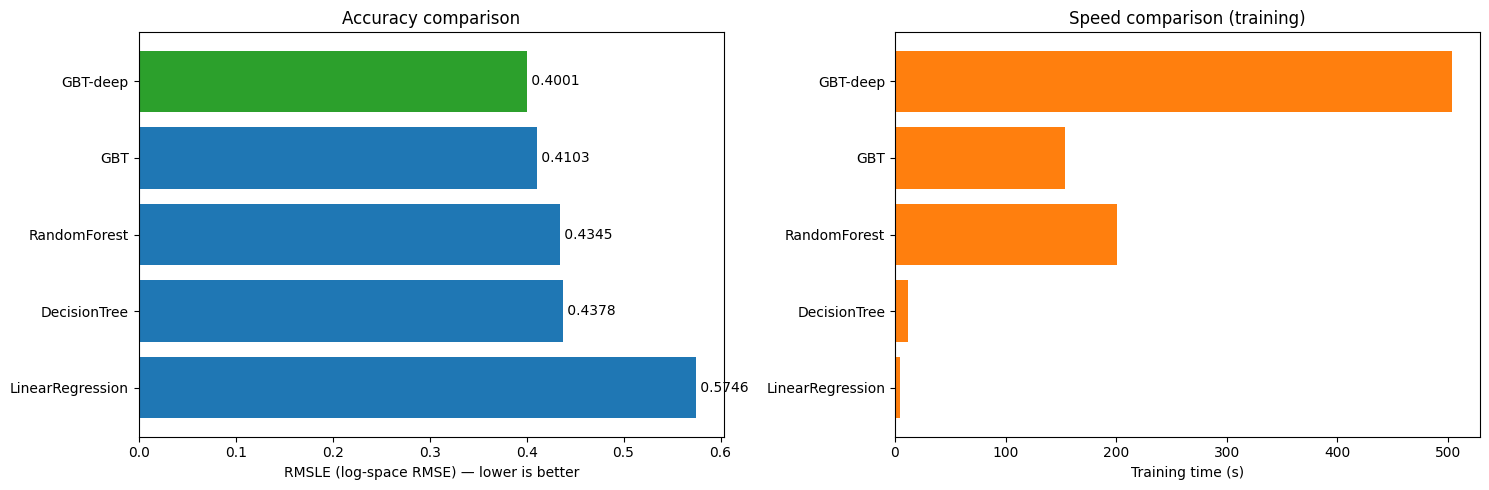



PER-SEGMENT ERROR ANALYSIS — GBT-deep



--- Per distance bin (km) ---
 distance_bin     n  rmse_sec  mae_sec   mape
            0 36404 2996.9800 244.4100 0.4500
            1 71582 3053.9700 261.6300 0.2900
            2 43146 3075.3300 293.6400 0.2300
            3 23550 3381.2900 348.0000 0.2200
            4 14394 3457.1600 379.7800 0.2000
            5  9593 2757.1800 354.1600 0.2000
            6  6612 3635.0600 445.1100 0.2100
            7  4323 3962.8700 487.4700 0.2000
            8  3722 3662.6000 478.4300 0.2000
            9  4251 2282.6600 405.6600 0.1800
           10  2722 2926.8200 491.5500 0.1800
           11  1525 5306.0700 712.8700 0.1900
           12  1139  609.8700 408.4400 0.1800
           13  1076 3609.2000 548.3600 0.1900
           14   868 4034.5600 622.7700 0.1800
           15   686 4519.0900 680.2400 0.2100
           16   611  622.6500 429.3900 0.1700
           17   581 5999.8700 884.6400 0.1800
           18   599 5059.4700 814.8100 0.1800
           19  1287 5441.5000 842.0500 0.2000
   


--- Per hour of day ---
 hour     n  rmse_sec  mae_sec
    0  9093 3069.2000 290.9000
    1  6334 4115.4000 358.4000
    2  4421 4510.1000 390.1000
    3  3278 5328.5000 479.0000
    4  2541 3982.0000 341.1000
    5  2505 3420.1000 283.5000
    6  5621 2163.5000 196.6000
    7  9015 2114.2000 229.1000
    8 10876 2948.2000 304.7000
    9 11059 2434.3000 274.9000
   10 10528 2807.2000 300.8000
   11 11216 3021.3000 329.5000
   12 11536 3944.6000 410.7000
   13 11416 3616.7000 401.9000
   14 11568 3394.1000 390.3000
   15 10851 3407.9000 391.3000
   16  9794 3425.0000 394.6000
   17 11472 2520.9000 330.2000
   18 14009 3143.9000 340.5000
   19 14099 3125.1000 307.6000
   20 12726 3013.5000 267.7000
   21 13647 3093.6000 275.3000
   22 13299 3610.2000 332.1000
   23 11818 2599.0000 258.7000



--- Per vendor ---
 vendor      n  rmse_sec  mae_sec
      1 109173  332.6000 199.9000
      2 123549 4404.6000 435.7000



--- Per trip type ---
    trip_type      n  rmse_sec  mae_sec   mape
      airport  11997 2883.1900 515.5400 0.2000
    manhattan 217352 3239.8100 314.6500 0.2800
outer_borough   3373 2871.2700 321.0700 0.3000


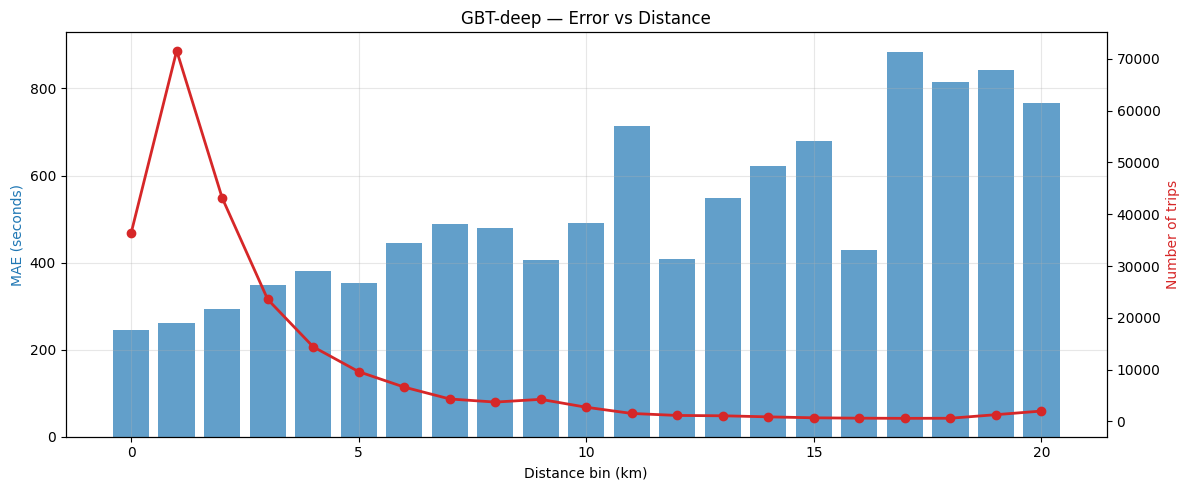


FEATURE IMPORTANCE (top 15 for each tree model)

--- RandomForest ---
            feature  importance_pct
       haversine_km         47.1400
       distance_bin         32.1300
   dropoff_latitude          3.2300
  dropoff_longitude          2.1600
        pickup_hour          2.1200
    pickup_hour_cos          2.0800
  is_airport_pickup          2.0600
       is_manhattan          1.9600
   pickup_longitude          1.8000
      is_jfk_pickup          0.7800
     pickup_dow_cos          0.7500
    pickup_hour_sin          0.7500
    pickup_latitude          0.6900
slow_trip_indicator          0.6900
         is_weekend          0.5800

--- GBT ---
           feature  importance_pct
      haversine_km         47.4700
  dropoff_latitude         10.1500
  pickup_longitude          7.1900
 dropoff_longitude          6.7800
   pickup_latitude          6.2200
       pickup_hour          4.8300
   pickup_hour_cos          3.6000
  pickup_dayofweek          2.8300
      distance_bin       

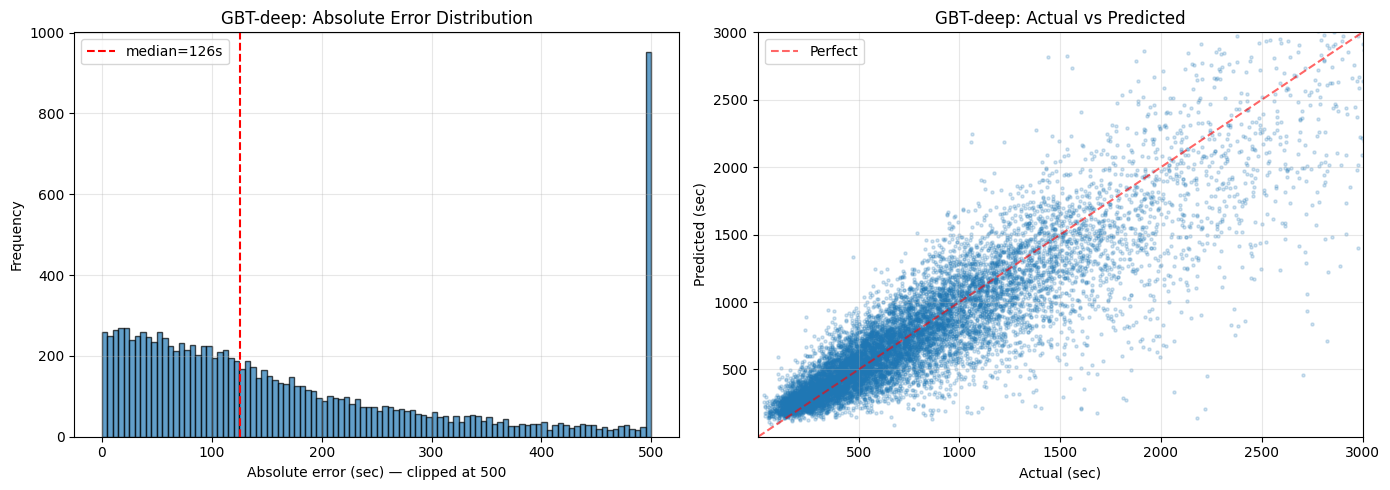


RECOMMENDATION

Accuracy ranking (best to worst):
  1. GBT-deep             RMSLE = 0.4001
  2. GBT                  RMSLE = 0.4103
  3. RandomForest         RMSLE = 0.4345
  4. DecisionTree         RMSLE = 0.4378
  5. LinearRegression     RMSLE = 0.5746

Improvement over LinearRegression baseline:
  DecisionTree : +23.8%
  RandomForest : +24.4%
  GBT          : +28.6%
  GBT-deep     : +30.4%



✅ Done. Train/valid unpersisted.


In [18]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import functions as F
from pyspark.ml.functions import vector_to_array
from pyspark.ml.regression import (
    LinearRegression, DecisionTreeRegressor,
    RandomForestRegressor, GBTRegressor,
)
from pyspark.ml.evaluation import RegressionEvaluator

# ---------- Safety: rebuild FEATURE_COLS if not in scope ----------
FEATURE_COLS = [
    "vendor_id",
    "passenger_count",
    "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude",
    "store_and_fwd_flag_y",
    "pickup_hour", "pickup_dayofweek", "pickup_month",
    "is_weekend", "is_rush_hour", "is_late_night",
    "pickup_hour_sin", "pickup_hour_cos",
    "pickup_dow_sin",  "pickup_dow_cos",
    "pickup_month_sin","pickup_month_cos",
    "haversine_km", "distance_bin",
    "is_jfk_pickup", "is_lga_pickup", "is_airport_pickup",
    "is_manhattan", "slow_trip_indicator",
    "is_group_trip", "vendor_rush", "vendor_x_group_idx",
]

assert len(FEATURE_COLS) == 29, f"Expected 29 features, got {len(FEATURE_COLS)}"

# ---------- Persist train/valid for reuse ----------
print("Persisting train/valid DataFrames...")
train_df = data["train"].persist()
valid_df = data["valid"].persist()
n_train = train_df.count()
n_valid = valid_df.count()
print(f"Train: {n_train:,} | Valid: {n_valid:,}")

# ---------- Evaluators ----------
eval_rmse = RegressionEvaluator(
    labelCol="log_trip_duration", predictionCol="prediction", metricName="rmse")
eval_mae  = RegressionEvaluator(
    labelCol="log_trip_duration", predictionCol="prediction", metricName="mae")
eval_r2   = RegressionEvaluator(
    labelCol="log_trip_duration", predictionCol="prediction", metricName="r2")

MAX_SEC = 86400.0


def evaluate(model, name, train_time_s):
    """Compute all metrics + keep prediction df for analysis."""
    t0 = time.time()
    preds = model.transform(valid_df)
    pred_time = time.time() - t0

    # clip predictions to sensible range in seconds
    preds = preds.withColumn(
        "pred_sec",
        F.greatest(F.lit(1.0), F.least(F.lit(MAX_SEC), F.expm1("prediction"))),
    )

    rmse_log = eval_rmse.evaluate(preds)
    mae_log  = eval_mae.evaluate(preds)
    r2_log   = eval_r2.evaluate(preds)

    sec_stats = preds.select(
        F.sqrt(F.mean((F.col("pred_sec") - F.col("trip_duration"))**2)).alias("rmse_sec"),
        F.mean(F.abs(F.col("pred_sec") - F.col("trip_duration"))).alias("mae_sec"),
        F.expr("percentile_approx(ABS(pred_sec - trip_duration), 0.5)").alias("medae_sec"),
        F.expr("percentile_approx(ABS(pred_sec - trip_duration), 0.95)").alias("p95ae_sec"),
    ).collect()[0]

    return {
        "model": name,
        "train_time_s": train_time_s,
        "pred_time_s": pred_time,
        "rmse_log": rmse_log,
        "mae_log": mae_log,
        "r2_log": r2_log,
        "rmse_sec": float(sec_stats["rmse_sec"]),
        "mae_sec": float(sec_stats["mae_sec"]),
        "medae_sec": float(sec_stats["medae_sec"]),
        "p95ae_sec": float(sec_stats["p95ae_sec"]),
    }


# ============================================================
# TRAIN ALL MODELS
# ============================================================
results = []
preds_store = {}   # name → prediction DataFrame (for detailed analysis)

print("\n" + "=" * 80)
print("TRAINING 5 MODELS")
print("=" * 80)

# ---------- 1. Linear Regression ----------
print("\n[1/5] LinearRegression...")
t0 = time.time()
lr = LinearRegression(
    featuresCol="features", labelCol="log_trip_duration",
    regParam=0.01, elasticNetParam=0.0,
    maxIter=100, standardization=True,
)
model_lr = lr.fit(train_df)
m = evaluate(model_lr, "LinearRegression", time.time() - t0)
results.append(m); preds_store["LinearRegression"] = None
print(f"      RMSLE={m['rmse_log']:.4f} | MAE={m['mae_sec']:.1f}s | "
      f"train {m['train_time_s']:.1f}s | pred {m['pred_time_s']:.1f}s")

# ---------- 2. Decision Tree ----------
print("\n[2/5] DecisionTreeRegressor...")
t0 = time.time()
dt = DecisionTreeRegressor(
    featuresCol="features", labelCol="log_trip_duration",
    maxDepth=10, maxBins=64, seed=42,
)
model_dt = dt.fit(train_df)
m = evaluate(model_dt, "DecisionTree", time.time() - t0)
results.append(m); preds_store["DecisionTree"] = None
print(f"      RMSLE={m['rmse_log']:.4f} | MAE={m['mae_sec']:.1f}s | "
      f"train {m['train_time_s']:.1f}s | pred {m['pred_time_s']:.1f}s")

# ---------- 3. Random Forest ----------
print("\n[3/5] RandomForestRegressor...")
t0 = time.time()
rf = RandomForestRegressor(
    featuresCol="features", labelCol="log_trip_duration",
    numTrees=50, maxDepth=10, maxBins=64, seed=42,
)
model_rf = rf.fit(train_df)
m = evaluate(model_rf, "RandomForest", time.time() - t0)
results.append(m); preds_store["RandomForest"] = None
print(f"      RMSLE={m['rmse_log']:.4f} | MAE={m['mae_sec']:.1f}s | "
      f"train {m['train_time_s']:.1f}s | pred {m['pred_time_s']:.1f}s")

# ---------- 4. Gradient Boosted Trees ----------
print("\n[4/5] GBTRegressor (this takes the longest)...")
t0 = time.time()
gbt = GBTRegressor(
    featuresCol="features", labelCol="log_trip_duration",
    maxIter=50, maxDepth=6, stepSize=0.1,
    subsamplingRate=0.8, seed=42,
)
model_gbt = gbt.fit(train_df)
m = evaluate(model_gbt, "GBT", time.time() - t0)
results.append(m); preds_store["GBT"] = None
print(f"      RMSLE={m['rmse_log']:.4f} | MAE={m['mae_sec']:.1f}s | "
      f"train {m['train_time_s']:.1f}s | pred {m['pred_time_s']:.1f}s")

# ---------- 5. GBT (deeper, tuned) ----------
print("\n[5/5] GBTRegressor (tuned, deeper)...")
t0 = time.time()
gbt2 = GBTRegressor(
    featuresCol="features", labelCol="log_trip_duration",
    maxIter=100, maxDepth=8, stepSize=0.05,
    subsamplingRate=0.8, seed=42,
)
model_gbt2 = gbt2.fit(train_df)
m = evaluate(model_gbt2, "GBT-deep", time.time() - t0)
results.append(m); preds_store["GBT-deep"] = None
print(f"      RMSLE={m['rmse_log']:.4f} | MAE={m['mae_sec']:.1f}s | "
      f"train {m['train_time_s']:.1f}s | pred {m['pred_time_s']:.1f}s")


# ============================================================
# 1. MAIN COMPARISON TABLE
# ============================================================
print("\n\n" + "=" * 110)
print("MAIN COMPARISON TABLE")
print("=" * 110)

df_results = pd.DataFrame(results).sort_values("rmse_log")
df_results["rank"] = range(1, len(df_results) + 1)

display_cols = [
    "rank", "model",
    "rmse_log", "mae_log", "r2_log",
    "mae_sec", "medae_sec", "p95ae_sec", "rmse_sec",
    "train_time_s", "pred_time_s",
]
df_show = df_results[display_cols].copy()
for c in ["rmse_log", "mae_log", "r2_log"]:
    df_show[c] = df_show[c].round(4)
for c in ["mae_sec", "medae_sec", "p95ae_sec", "rmse_sec"]:
    df_show[c] = df_show[c].round(1)
for c in ["train_time_s", "pred_time_s"]:
    df_show[c] = df_show[c].round(1)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
print(df_show.to_string(index=False))

print("\nNote: rmse_log == RMSLE in the original seconds (same metric)")
print("      Lower is better for all error metrics.")
print("      r2_log is on log-transformed target (higher is better, max 1.0)")

best_model_name = df_results.iloc[0]["model"]
print(f"\n🏆 Best model: {best_model_name} (RMSLE={df_results.iloc[0]['rmse_log']:.4f})")


# ============================================================
# 2. VISUAL COMPARISON — accuracy vs speed
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# RMSLE bar
ax = axes[0]
df_plot = df_results.sort_values("rmse_log")
colors = ["#2ca02c" if i == 0 else "#1f77b4" for i in range(len(df_plot))]
bars = ax.barh(df_plot["model"], df_plot["rmse_log"], color=colors)
ax.set_xlabel("RMSLE (log-space RMSE) — lower is better")
ax.set_title("Accuracy comparison")
ax.invert_yaxis()
for bar, v in zip(bars, df_plot["rmse_log"]):
    ax.text(v, bar.get_y() + bar.get_height() / 2, f" {v:.4f}",
            va="center", fontsize=10)

# Time bar
ax = axes[1]
ax.barh(df_plot["model"], df_plot["train_time_s"], color="#ff7f0e")
ax.set_xlabel("Training time (s)")
ax.set_title("Speed comparison (training)")
ax.invert_yaxis()

plt.tight_layout()
plt.show()


# ============================================================
# 3. PER-SEGMENT ANALYSIS (using best model)
# ============================================================
print(f"\n\n{'='*110}")
print(f"PER-SEGMENT ERROR ANALYSIS — {best_model_name}")
print(f"{'='*110}")

best_model = {
    "LinearRegression": model_lr,
    "DecisionTree":     model_dt,
    "RandomForest":     model_rf,
    "GBT":              model_gbt,
    "GBT-deep":         model_gbt2,
}[best_model_name]

best_preds = best_model.transform(valid_df).withColumn(
    "pred_sec",
    F.greatest(F.lit(1.0), F.least(F.lit(MAX_SEC), F.expm1("prediction"))),
).withColumn(
    "abs_err", F.abs(F.col("pred_sec") - F.col("trip_duration")),
).withColumn(
    "sq_err", (F.col("pred_sec") - F.col("trip_duration"))**2,
)

# ---- 3a. Per distance bin ----
dist_pos = FEATURE_COLS.index("distance_bin")
per_dist = (
    best_preds
    .withColumn("distance_bin",
        vector_to_array("features")[dist_pos].cast("int"))
    .filter(F.col("distance_bin") <= 20)
    .groupBy("distance_bin")
    .agg(
        F.count("*").alias("n"),
        F.sqrt(F.mean("sq_err")).alias("rmse_sec"),
        F.mean("abs_err").alias("mae_sec"),
        F.mean(F.col("abs_err") / F.col("trip_duration")).alias("mape"),
    )
    .orderBy("distance_bin")
    .toPandas()
)
print("\n--- Per distance bin (km) ---")
print(per_dist.round(2).to_string(index=False))

# ---- 3b. Per hour ----
hour_pos = FEATURE_COLS.index("pickup_hour")
per_hour = (
    best_preds
    .withColumn("hour", vector_to_array("features")[hour_pos].cast("int"))
    .groupBy("hour")
    .agg(
        F.count("*").alias("n"),
        F.sqrt(F.mean("sq_err")).alias("rmse_sec"),
        F.mean("abs_err").alias("mae_sec"),
    )
    .orderBy("hour")
    .toPandas()
)
print("\n--- Per hour of day ---")
print(per_hour.round(1).to_string(index=False))

# ---- 3c. Per vendor ----
vendor_pos = FEATURE_COLS.index("vendor_id")
per_vendor = (
    best_preds
    .withColumn("vendor", vector_to_array("features")[vendor_pos].cast("int"))
    .groupBy("vendor")
    .agg(
        F.count("*").alias("n"),
        F.sqrt(F.mean("sq_err")).alias("rmse_sec"),
        F.mean("abs_err").alias("mae_sec"),
    )
    .orderBy("vendor")
    .toPandas()
)
print("\n--- Per vendor ---")
print(per_vendor.round(1).to_string(index=False))

# ---- 3d. Airport vs city ----
air_pos = FEATURE_COLS.index("is_airport_pickup")
manh_pos = FEATURE_COLS.index("is_manhattan")

per_type = (
    best_preds
    .withColumn("airport", vector_to_array("features")[air_pos].cast("int"))
    .withColumn("manhattan", vector_to_array("features")[manh_pos].cast("int"))
    .withColumn("trip_type",
        F.when(F.col("airport") == 1, "airport")
        .when(F.col("manhattan") == 1, "manhattan")
        .otherwise("outer_borough"))
    .groupBy("trip_type")
    .agg(
        F.count("*").alias("n"),
        F.sqrt(F.mean("sq_err")).alias("rmse_sec"),
        F.mean("abs_err").alias("mae_sec"),
        F.mean(F.col("abs_err") / F.col("trip_duration")).alias("mape"),
    )
    .orderBy("trip_type")
    .toPandas()
)
print("\n--- Per trip type ---")
print(per_type.round(2).to_string(index=False))

# ---- Plot per distance bin ----
fig, ax = plt.subplots(figsize=(12, 5))
ax2 = ax.twinx()

bars = ax.bar(per_dist["distance_bin"], per_dist["mae_sec"],
              color="#1f77b4", alpha=0.7, label="MAE (sec)")
line = ax2.plot(per_dist["distance_bin"], per_dist["n"],
                color="#d62728", marker="o", linewidth=2, label="Volume")

ax.set_xlabel("Distance bin (km)")
ax.set_ylabel("MAE (seconds)", color="#1f77b4")
ax2.set_ylabel("Number of trips", color="#d62728")
ax.set_title(f"{best_model_name} — Error vs Distance")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# 4. FEATURE IMPORTANCE (tree models only)
# ============================================================
print(f"\n{'='*110}")
print("FEATURE IMPORTANCE (top 15 for each tree model)")
print(f"{'='*110}")

for model, model_name in [(model_rf, "RandomForest"),
                          (model_gbt, "GBT"),
                          (model_gbt2, "GBT-deep")]:
    imp = model.featureImportances.toArray()
    df_imp = pd.DataFrame({
        "feature": FEATURE_COLS,
        "importance": imp,
    }).sort_values("importance", ascending=False).head(15)
    df_imp["importance_pct"] = (df_imp["importance"] * 100).round(2)

    print(f"\n--- {model_name} ---")
    print(df_imp[["feature", "importance_pct"]].to_string(index=False))


# ============================================================
# 5. Residual distribution (best model)
# ============================================================
print(f"\n{'='*110}")
print(f"RESIDUAL ANALYSIS — {best_model_name}")
print(f"{'='*110}")

residual_sample = (
    best_preds
    .select("trip_duration", "pred_sec", "abs_err")
    .sample(fraction=0.05, seed=42)
    .toPandas()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Abs error distribution
ax = axes[0]
ax.hist(residual_sample["abs_err"].clip(0, 500), bins=100,
        color="#1f77b4", edgecolor="black", alpha=0.7)
ax.set_xlabel("Absolute error (sec) — clipped at 500")
ax.set_ylabel("Frequency")
ax.set_title(f"{best_model_name}: Absolute Error Distribution")
ax.grid(True, alpha=0.3)
ax.axvline(residual_sample["abs_err"].median(), color="red",
           linestyle="--", label=f"median={residual_sample['abs_err'].median():.0f}s")
ax.legend()

# Actual vs predicted
ax = axes[1]
ax.scatter(residual_sample["trip_duration"],
           residual_sample["pred_sec"],
           alpha=0.2, s=5, color="#1f77b4")
lim = [1, 3000]
ax.plot(lim, lim, "r--", alpha=0.6, label="Perfect")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Actual (sec)")
ax.set_ylabel("Predicted (sec)")
ax.set_title(f"{best_model_name}: Actual vs Predicted")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 6. RECOMMENDATION
# ============================================================
print(f"\n{'='*110}")
print("RECOMMENDATION")
print(f"{'='*110}")

lr_res = next(r for r in results if r["model"] == "LinearRegression")
dt_res = next(r for r in results if r["model"] == "DecisionTree")
rf_res = next(r for r in results if r["model"] == "RandomForest")
gbt_res = next(r for r in results if r["model"] == "GBT")
gbt2_res = next(r for r in results if r["model"] == "GBT-deep")

print(f"""
Accuracy ranking (best to worst):
  1. {df_results.iloc[0]['model']:20s} RMSLE = {df_results.iloc[0]['rmse_log']:.4f}
  2. {df_results.iloc[1]['model']:20s} RMSLE = {df_results.iloc[1]['rmse_log']:.4f}
  3. {df_results.iloc[2]['model']:20s} RMSLE = {df_results.iloc[2]['rmse_log']:.4f}
  4. {df_results.iloc[3]['model']:20s} RMSLE = {df_results.iloc[3]['rmse_log']:.4f}
  5. {df_results.iloc[4]['model']:20s} RMSLE = {df_results.iloc[4]['rmse_log']:.4f}

Improvement over LinearRegression baseline:
  DecisionTree : {(lr_res['rmse_log'] - dt_res['rmse_log']) / lr_res['rmse_log'] * 100:+.1f}%
  RandomForest : {(lr_res['rmse_log'] - rf_res['rmse_log']) / lr_res['rmse_log'] * 100:+.1f}%
  GBT          : {(lr_res['rmse_log'] - gbt_res['rmse_log']) / lr_res['rmse_log'] * 100:+.1f}%
  GBT-deep     : {(lr_res['rmse_log'] - gbt2_res['rmse_log']) / lr_res['rmse_log'] * 100:+.1f}%

""")

# ---------- cleanup ----------
train_df.unpersist()
valid_df.unpersist()
print("\n✅ Done. Train/valid unpersisted.")